<a href="https://colab.research.google.com/github/Tshoki-m/Capstone-Research/blob/main/PEPITA_MNIST_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PEPITA reproduction on MNIST (GPU / Colab)

Reproduction of the MNIST experiments in *Forward Learning with Top-Down Feedback: Empirical and Analytical Characterization* (Srinivasan et al.), using the hyperparameters from the paper's Tables 4 and 5.

**Before running:** `Runtime → Change runtime type → GPU` (T4 is fine).

**Workflow**
1. Run the setup, config, data and model cells.
2. Run the **smoke test** (2 epochs) and check accuracy and time per epoch.
3. Run the full experiment with `SEEDS = [0]` first, then `SEEDS = list(range(10))` for the final numbers (the paper averages 10 runs).
4. Results are saved per run as JSON (to Google Drive if enabled), so a disconnected session resumes where it stopped.

## Implementation choices to check against your repo

This notebook is a **self-contained re-implementation written from the paper's equations (Eqs. 1-6, Algorithm 1)**, not a copy of the original repository, so a few details the paper leaves open are fixed here. Each one is a setting in `BASE` so you can flip it and compare with your repo's behaviour.

| Choice | Default | Note |
|---|---|---|
| Biases | none (`use_bias=False`) | the paper writes only weight matrices W |
| Output / error | softmax output, `e = softmax(logits) - y` (`output_act='softmax'`) | paper writes `e = h_L - y`; set `'linear'` to use raw logits |
| Dropout in the modulated pass | **same mask** as the clean pass | different masks would swamp the small `Fe` perturbation |
| Modulated input | `x - F e` (paper's sign convention) | sign is irrelevant because F is symmetric around zero |
| F init (He-uniform) | U(-b, b), `b = 0.05*sqrt(6/fan_in)` | Table 4 writes `0.05*2*sqrt(6/fan_in)`, which can be read as the range width (used here) or as the bound; if your repo uses the larger one, set `F_scale=0.1` |
| F init (He-normal) | N(0, (0.05*sqrt(2/fan_in))^2) | as in Table 4 |
| Optimizer | SGD, momentum 0.9, weight decay as in tables | momentum matches your CIFAR-10 config; the Fig. 2 caption mentions a "vanilla" variant without it |
| Data | MNIST mean/std normalisation, no augmentation, flattened | |
| Reported accuracy | **final-epoch** test accuracy, mean and sample std (ddof=1) over seeds | best-epoch is also stored but picking it on the test set is optimistic |
| Alignment angle | angle between `vec(W_L ... W_1)` and `vec(F^T)` in degrees | my reading of the angle between F and W_tot in Figs. 3c, 9, 10 |

In [1]:
import os, json, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as Fn
from torchvision import datasets

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
if device.type != "cuda":
    print("WARNING: no GPU found. Use Runtime > Change runtime type > GPU.")
torch.backends.cuda.matmul.allow_tf32 = False   # keep full fp32 for fidelity
print("torch", torch.__version__)

# ---- where results are saved
SAVE_TO_DRIVE = True
OUT_DIR = "/content/PEPITA_results"
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = "/content/drive/MyDrive/PEPITA_MNIST_results"
    except Exception as ex:
        print("Drive not mounted, saving locally:", ex)
os.makedirs(OUT_DIR, exist_ok=True)
print("results dir:", OUT_DIR)

device: cuda Tesla T4
torch 2.11.0+cu130
Mounted at /content/drive
results dir: /content/drive/MyDrive/PEPITA_MNIST_results


In [2]:
# ------------------------------------------------------------------ config
BASE = dict(
    dataset="mnist", algo="pepita",            # algo: "pepita" or "bp"
    hidden_layers=1, hidden_units=1024,
    init="he_uniform",                          # "he_uniform" or "he_normal"
    lr=0.1, momentum=0.9, weight_decay=0.0, dropout=0.1,
    batch_size=64, epochs=100, lr_milestones=[60, 90], lr_gamma=0.1,
    F_scale=0.05,                               # feedback-matrix scale (see notes above)
    use_bias=False, output_act="softmax",
)

# Hyperparameters from the paper (Table 4: 1 hidden layer, Table 5: 2 and 3 hidden layers, MNIST column)
PRESETS = {
    # ---- PEPITA, MNIST
    "1h_noWD": dict(hidden_layers=1, lr=0.1,   weight_decay=0.0),
    "1h_WD":   dict(hidden_layers=1, lr=0.1,   weight_decay=1e-5),
    "2h_noWD": dict(hidden_layers=2, lr=0.1,   weight_decay=0.0),
    "2h_WD":   dict(hidden_layers=2, lr=0.1,   weight_decay=1e-5),
    "3h_noWD": dict(hidden_layers=3, lr=0.001, weight_decay=0.0,  lr_milestones=[]),   # no LR decay (Table 5 footnote)
    "3h_WD":   dict(hidden_layers=3, lr=0.001, weight_decay=1e-5, lr_milestones=[]),
    # ---- backprop baseline, MNIST (Table 1)
    "bp_1h_noWD": dict(algo="bp", hidden_layers=1, lr=0.1, weight_decay=0.0),
    "bp_1h_WD":   dict(algo="bp", hidden_layers=1, lr=0.1, weight_decay=1e-5),
    # ---- sanity control: F = 0 means hidden layers get no learning signal (only the last layer trains)
    "1h_noWD_F0": dict(hidden_layers=1, lr=0.1, weight_decay=0.0, F_scale=0.0),
    # ---- pipeline check against your own CIFAR-10 run (same config as your report, Table 5.1)
    "cifar_1h_WD": dict(dataset="cifar10", hidden_layers=1, lr=0.01, weight_decay=1e-4),
}

# Paper targets: (mean, std) of final test accuracy [%]
PAPER = {
    "1h_noWD": (98.02, 0.08), "1h_WD": (98.12, 0.08),
    "2h_noWD": (98.19, 0.07), "2h_WD": (98.09, 0.07),
    "3h_noWD": (95.07, 0.11), "3h_WD": (95.09, 0.16),
    "bp_1h_noWD": (98.72, 0.06), "bp_1h_WD": (98.66, 0.04),
    "cifar_1h_WD": (53.05, 0.23),
}

def get_cfg(name, **overrides):
    cfg = {**BASE, **PRESETS[name], **overrides}
    cfg["preset"] = name
    return cfg

In [3]:
# ------------------------------------------------------------------ data (whole dataset lives on the GPU)
_DATA = {}

def get_data(name):
    if name in _DATA:
        return _DATA[name]
    root = "/content/data"
    if name == "mnist":
        tr = datasets.MNIST(root, train=True, download=True)
        te = datasets.MNIST(root, train=False, download=True)
        mean, std = (0.1307,), (0.3081,)
        def prep(ds):
            return ds.data.float().div(255.0).unsqueeze(1), ds.targets.long()
    elif name == "cifar10":
        tr = datasets.CIFAR10(root, train=True, download=True)
        te = datasets.CIFAR10(root, train=False, download=True)
        mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
        def prep(ds):
            X = torch.tensor(ds.data).float().div(255.0).permute(0, 3, 1, 2)
            return X, torch.tensor(ds.targets).long()
    else:
        raise ValueError(name)
    m = torch.tensor(mean).view(1, -1, 1, 1)
    s = torch.tensor(std).view(1, -1, 1, 1)
    Xtr, Ytr = prep(tr)
    Xte, Yte = prep(te)
    Xtr = ((Xtr - m) / s).flatten(1)
    Xte = ((Xte - m) / s).flatten(1)
    _DATA[name] = tuple(t.to(device) for t in (Xtr, Ytr, Xte, Yte))
    print(name, "train", tuple(_DATA[name][0].shape), "test", tuple(_DATA[name][2].shape))
    return _DATA[name]

_ = get_data("mnist")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.85MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.37MB/s]


mnist train (60000, 784) test (10000, 784)


In [4]:
# ------------------------------------------------------------------ model
class FCNet(nn.Module):
    def __init__(self, in_dim, hidden_units, n_hidden, n_out, bias, init):
        super().__init__()
        dims = [in_dim] + [hidden_units] * n_hidden + [n_out]
        self.layers = nn.ModuleList(
            [nn.Linear(dims[i], dims[i + 1], bias=bias) for i in range(len(dims) - 1)])
        for lin in self.layers:
            fan_in = lin.in_features
            if init == "he_uniform":
                bound = math.sqrt(6.0 / fan_in)
                nn.init.uniform_(lin.weight, -bound, bound)
            elif init == "he_normal":
                nn.init.normal_(lin.weight, 0.0, math.sqrt(2.0 / fan_in))
            else:
                raise ValueError(init)
            if lin.bias is not None:
                nn.init.zeros_(lin.bias)

    def forward(self, x, masks=None):
        """Returns ([h_1 ... h_{L-1}], logits). Optional dropout masks are applied to hidden activations."""
        hs, h = [], x
        for i, lin in enumerate(self.layers[:-1]):
            h = Fn.relu(lin(h))
            if masks is not None:
                h = h * masks[i]
            hs.append(h)
        return hs, self.layers[-1](h)


def make_F(in_dim, out_dim, init, scale):
    """Fixed random feedback matrix F (in_dim x out_dim) projecting the error onto the input."""
    if init == "he_uniform":
        b = scale * math.sqrt(6.0 / in_dim)
        return (torch.rand(in_dim, out_dim) * 2 - 1) * b
    return torch.randn(in_dim, out_dim) * scale * math.sqrt(2.0 / in_dim)


def sample_masks(net, B, p):
    if p <= 0:
        return None
    return [(torch.rand(B, lin.out_features, device=device) > p).float() / (1.0 - p)
            for lin in net.layers[:-1]]


def out_act(logits, mode):
    return torch.softmax(logits, dim=1) if mode == "softmax" else logits


@torch.no_grad()
def pepita_step(net, F, opt, x, y, y1h, cfg):
    """One PEPITA update (Algorithm 1), batch-averaged. The same dropout masks are used in both passes."""
    B = x.shape[0]
    masks = sample_masks(net, B, cfg["dropout"])
    hs, logits = net(x, masks)                      # clean pass
    e = out_act(logits, cfg["output_act"]) - y1h    # error
    Fe = e @ F.T                                    # (B, D)
    x_mod = x - Fe                                  # modulated input
    hs_err, _ = net(x_mod, masks)                   # modulated pass
    L = len(net.layers)
    for l, lin in enumerate(net.layers):
        pre = x_mod if l == 0 else hs_err[l - 1]
        delta = (hs[l] - hs_err[l]) if l < L - 1 else e
        lin.weight.grad = delta.T @ pre / B         # Eqs. (3), (4), (5)
        if lin.bias is not None:
            lin.bias.grad = delta.mean(0)
    opt.step()
    loss = Fn.cross_entropy(logits, y)
    ratio = Fe.norm() / x.norm()                    # ||Fe|| / ||x||, should stay << 1
    return loss, ratio


def bp_step(net, opt, x, y, cfg):
    masks = sample_masks(net, x.shape[0], cfg["dropout"])
    _, logits = net(x, masks)
    loss = Fn.cross_entropy(logits, y)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    return loss.detach()


@torch.no_grad()
def evaluate(net, X, Y, bs=10000):
    correct, loss = 0, 0.0
    for i in range(0, len(X), bs):
        _, lg = net(X[i:i + bs])
        correct += (lg.argmax(1) == Y[i:i + bs]).sum().item()
        loss += Fn.cross_entropy(lg, Y[i:i + bs], reduction="sum").item()
    return 100.0 * correct / len(X), loss / len(X)


@torch.no_grad()
def alignment_angle(net, F):
    """Angle (degrees) between vec(W_tot) and vec(F^T), W_tot = W_L ... W_1 (linear product)."""
    Wtot = net.layers[0].weight
    for lin in net.layers[1:]:
        Wtot = lin.weight @ Wtot
    a, b = Wtot.flatten(), F.T.flatten()
    cos = (a @ b) / (a.norm() * b.norm() + 1e-12)
    return math.degrees(math.acos(float(cos.clamp(-1, 1))))

In [5]:
# ------------------------------------------------------------------ one full training run
def run_one(cfg, seed, verbose=True):
    Xtr, Ytr, Xte, Yte = get_data(cfg["dataset"])
    torch.manual_seed(seed); np.random.seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    in_dim = Xtr.shape[1]
    net = FCNet(in_dim, cfg["hidden_units"], cfg["hidden_layers"], 10, cfg["use_bias"], cfg["init"]).to(device)
    pep = cfg["algo"] == "pepita"
    F = make_F(in_dim, 10, cfg["init"], cfg["F_scale"]).to(device) if pep else None
    opt = torch.optim.SGD(net.parameters(), lr=cfg["lr"], momentum=cfg["momentum"],
                          weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=cfg["lr_milestones"], gamma=cfg["lr_gamma"])
    N, bs = len(Xtr), cfg["batch_size"]
    Y1h = Fn.one_hot(Ytr, 10).float()
    gen = torch.Generator(device=device); gen.manual_seed(seed)
    hist, t0 = [], time.time()

    for ep in range(1, cfg["epochs"] + 1):
        lr_now = opt.param_groups[0]["lr"]
        perm = torch.randperm(N, device=device, generator=gen)
        loss_sum = torch.zeros((), device=device)
        ratio_sum = torch.zeros((), device=device)
        nb = 0
        for i in range(0, N, bs):
            idx = perm[i:i + bs]
            x, y, y1 = Xtr[idx], Ytr[idx], Y1h[idx]
            if pep:
                loss, ratio = pepita_step(net, F, opt, x, y, y1, cfg)
                ratio_sum += ratio
            else:
                loss = bp_step(net, opt, x, y, cfg)
            loss_sum += loss
            nb += 1
        sched.step()
        acc, tl = evaluate(net, Xte, Yte)
        rec = dict(epoch=ep, lr=lr_now, train_loss=loss_sum.item() / nb, test_loss=tl, test_acc=acc,
                   weight_norms=[lin.weight.norm().item() for lin in net.layers])
        if pep:
            rec["Fe_over_x"] = ratio_sum.item() / nb
            rec["angle_F_Wtot"] = alignment_angle(net, F)
        hist.append(rec)
        if verbose and (ep <= 3 or ep % 10 == 0 or ep == cfg["epochs"]):
            extra = f" | angle {rec['angle_F_Wtot']:.1f} | |Fe|/|x| {rec['Fe_over_x']:.3f}" if pep else ""
            print(f"[{cfg['preset']} seed {seed}] ep {ep:3d} lr {lr_now:.0e} "
                  f"train_loss {rec['train_loss']:.4f} test_acc {acc:.2f}{extra} "
                  f"({(time.time() - t0) / ep:.1f}s/epoch)")
    return dict(cfg=cfg, seed=seed, hist=hist, final_test_acc=hist[-1]["test_acc"],
                best_test_acc=max(h["test_acc"] for h in hist), runtime_s=time.time() - t0)


def run_preset(name, seeds, **overrides):
    """Runs (or resumes) a preset for each seed, saving one JSON per run."""
    out = []
    for s in seeds:
        path = os.path.join(OUT_DIR, f"{name}_seed{s}.json")
        if os.path.exists(path) and not overrides:
            print("loaded", path)
            out.append(json.load(open(path)))
            continue
        res = run_one(get_cfg(name, **overrides), s)
        if not overrides:
            json.dump(res, open(path, "w"))
        out.append(res)
    return out

## 1. Smoke test

Two epochs, one seed, nothing saved. Expect test accuracy above ~90% already after the first epoch, `|Fe|/|x|` well below 1, and a printed time per epoch. Multiply that time by 100 epochs and by the number of seeds to plan the full run.

In [6]:
smoke = run_one(get_cfg("1h_noWD", epochs=2), seed=0)
print("final acc after 2 epochs:", smoke["final_test_acc"])
print("estimated time for one 100-epoch run: %.1f min" % (smoke["runtime_s"] / 2 * 100 / 60))

[1h_noWD seed 0] ep   1 lr 1e-01 train_loss 1.5806 test_acc 93.49 | angle 76.8 | |Fe|/|x| 0.001 (1.9s/epoch)
[1h_noWD seed 0] ep   2 lr 1e-01 train_loss 0.9497 test_acc 91.36 | angle 71.4 | |Fe|/|x| 0.001 (1.4s/epoch)
final acc after 2 epochs: 91.36
estimated time for one 100-epoch run: 2.4 min


## 2. Full experiment

Start with `SEEDS = [0]` to check one complete run, then switch to `list(range(10))`. Finished runs are loaded from disk, so re-running the cell only trains the missing seeds.

Suggested order: `1h_noWD` and `1h_WD` first, then `bp_1h_*` as the baseline, then `2h_*` and `3h_*`. `cifar_1h_WD` re-runs your CIFAR-10 configuration in this notebook, so you can check it agrees with your existing repo result (paper: 53.05 +/- 0.23) before trusting the MNIST numbers. `1h_noWD_F0` is a control with no feedback signal to the hidden layer.

In [7]:
SEEDS = [0]                        # -> list(range(10)) for the final numbers
RUN = ["1h_noWD", "1h_WD"]         # add: "bp_1h_noWD", "bp_1h_WD", "2h_noWD", "2h_WD", "3h_noWD", "3h_WD", "1h_noWD_F0", "cifar_1h_WD"

for name in RUN:
    run_preset(name, SEEDS)

[1h_noWD seed 0] ep   1 lr 1e-01 train_loss 1.5806 test_acc 93.49 | angle 76.8 | |Fe|/|x| 0.001 (0.9s/epoch)
[1h_noWD seed 0] ep   2 lr 1e-01 train_loss 0.9497 test_acc 91.36 | angle 71.4 | |Fe|/|x| 0.001 (0.9s/epoch)
[1h_noWD seed 0] ep   3 lr 1e-01 train_loss 0.7564 test_acc 96.49 | angle 68.2 | |Fe|/|x| 0.001 (0.9s/epoch)
[1h_noWD seed 0] ep  10 lr 1e-01 train_loss 0.2867 test_acc 97.20 | angle 60.9 | |Fe|/|x| 0.000 (0.9s/epoch)
[1h_noWD seed 0] ep  20 lr 1e-01 train_loss 0.1288 test_acc 97.12 | angle 58.5 | |Fe|/|x| 0.000 (0.9s/epoch)
[1h_noWD seed 0] ep  30 lr 1e-01 train_loss 0.0488 test_acc 97.44 | angle 57.9 | |Fe|/|x| 0.000 (0.9s/epoch)
[1h_noWD seed 0] ep  40 lr 1e-01 train_loss 0.0371 test_acc 98.16 | angle 57.6 | |Fe|/|x| 0.000 (1.0s/epoch)
[1h_noWD seed 0] ep  50 lr 1e-01 train_loss 0.0210 test_acc 97.88 | angle 57.2 | |Fe|/|x| 0.000 (0.9s/epoch)
[1h_noWD seed 0] ep  60 lr 1e-01 train_loss 0.0211 test_acc 98.14 | angle 57.1 | |Fe|/|x| 0.000 (1.0s/epoch)
[1h_noWD seed 0] ep

## 3. Results vs the paper

In [8]:
def load_results(name):
    out = []
    for f in sorted(os.listdir(OUT_DIR)):
        if f.startswith(name + "_seed") and f.endswith(".json"):
            out.append(json.load(open(os.path.join(OUT_DIR, f))))
    return out

def summary(names):
    rows = []
    for n in names:
        rs = load_results(n)
        if not rs:
            continue
        fin = np.array([r["final_test_acc"] for r in rs])
        best = np.array([r["best_test_acc"] for r in rs])
        sd = fin.std(ddof=1) if len(fin) > 1 else float("nan")
        pm, ps = PAPER.get(n, (float("nan"), float("nan")))
        rows.append(dict(preset=n, runs=len(rs), final_mean=round(fin.mean(), 2), final_std=round(sd, 2),
                         best_epoch_mean=round(best.mean(), 2), paper_mean=pm, paper_std=ps,
                         diff_pp=round(fin.mean() - pm, 2)))
    return pd.DataFrame(rows)

ALL = list(PRESETS.keys())
df = summary(ALL)
df

,preset,runs,final_mean,final_std,best_epoch_mean,paper_mean,paper_std,diff_pp
0,1h_noWD,1,98.27,NaN,98.33,98.02,0.08,0.25
1,1h_WD,1,98.19,NaN,98.24,98.12,0.08,0.07


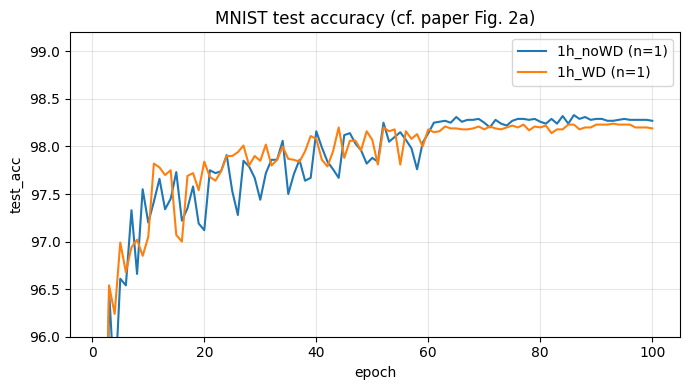

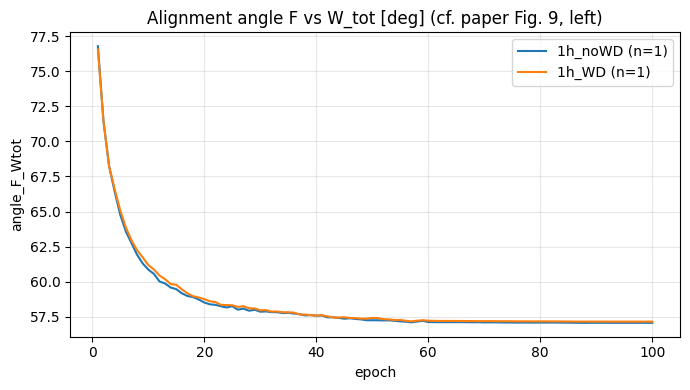

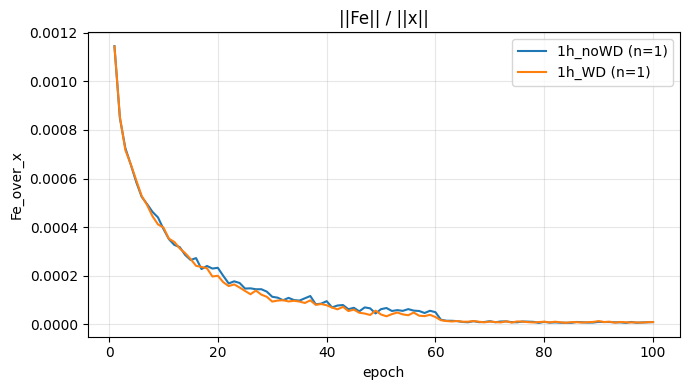

In [9]:
def plot_curves(names, key="test_acc", ylim=None, title=None):
    plt.figure(figsize=(7, 4))
    for n in names:
        rs = load_results(n)
        if not rs or key not in rs[0]["hist"][0]:
            continue
        Y = np.array([[h[key] for h in r["hist"]] for r in rs])
        x = np.arange(1, Y.shape[1] + 1)
        plt.plot(x, Y.mean(0), label=f"{n} (n={len(rs)})")
        if len(rs) > 1:
            plt.fill_between(x, Y.mean(0) - Y.std(0, ddof=1), Y.mean(0) + Y.std(0, ddof=1), alpha=0.2)
    plt.xlabel("epoch"); plt.ylabel(key); plt.grid(alpha=0.3); plt.legend()
    if ylim: plt.ylim(*ylim)
    plt.title(title or key); plt.tight_layout(); plt.show()

plot_curves(["1h_noWD", "1h_WD", "bp_1h_noWD"], "test_acc", ylim=(96, 99.2), title="MNIST test accuracy (cf. paper Fig. 2a)")
plot_curves(["1h_noWD", "1h_WD"], "angle_F_Wtot", title="Alignment angle F vs W_tot [deg] (cf. paper Fig. 9, left)")
plot_curves(["1h_noWD", "1h_WD"], "Fe_over_x", title="||Fe|| / ||x||")

## Notes for the report

- Report **final-epoch** accuracy as the main number; best-epoch is shown only for reference.
- Document every difference from the paper (see the table at the top): bias-free layers, softmax error, shared dropout mask, F initialisation reading, and the use of a re-implementation rather than the original code.
- If a preset lands more than a couple of standard deviations from the paper, first suspect the settings that the paper leaves ambiguous (`F_scale`, `output_act`, `use_bias`, momentum) before suspecting the algorithm. Changing one of them is a one-line override, e.g. `run_one(get_cfg("1h_noWD", F_scale=0.1), seed=0)`.
- Still to add for the full reproduction: activation normalisation, weight mirroring (with and without pre-mirroring) and the slowness metric from Table 3.